# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Intifada Afkar Lazain Muhammad | 5054251029 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

torch.manual_seed(42)
np.random.seed(42)
sns.set_style("whitegrid")

In [4]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv("/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv")

display(df.head())
print("Jumlah baris, kolom:", df.shape)
print()
df.info()
display(df.describe())
print("Missing value per kolom:")
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris, kolom: (10000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


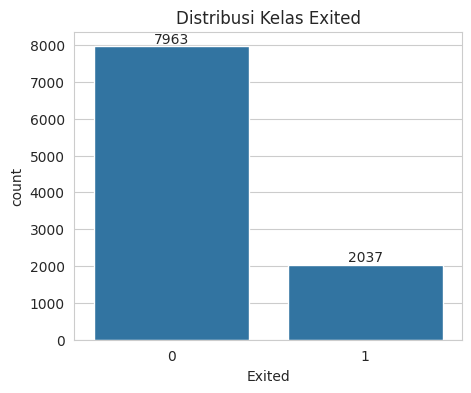

In [5]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

print(df["Exited"].value_counts())
print(df["Exited"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Exited", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Kelas Exited")
plt.show()
# Dataset imbalanced: kelas 0 (bertahan) sekitar 80%, kelas 1 (churn) sekitar 20%.

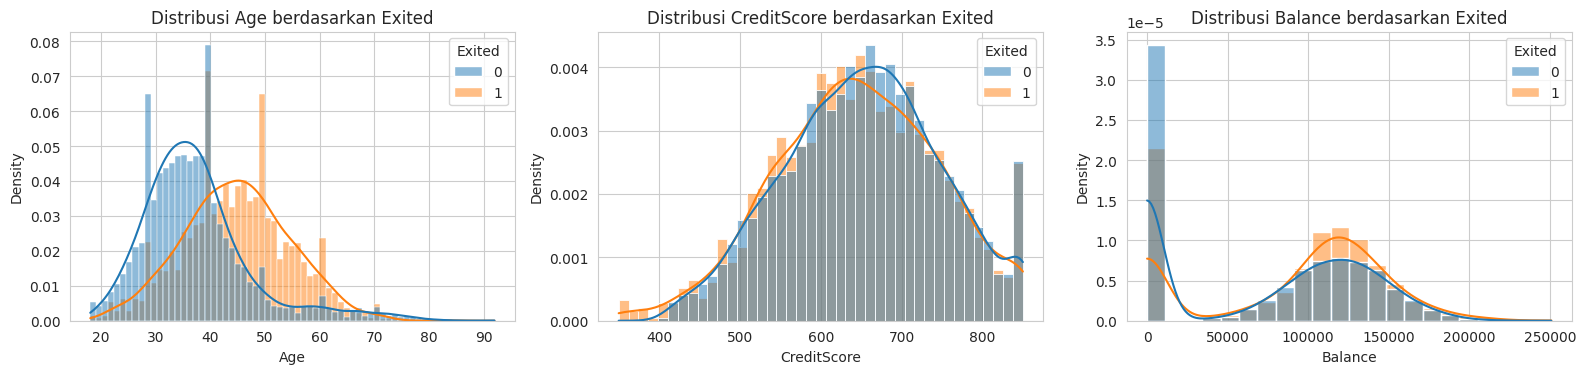

In [6]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

num_features = ["Age", "CreditScore", "Balance"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_features):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"Distribusi {col} berdasarkan Exited")
plt.tight_layout()
plt.show()

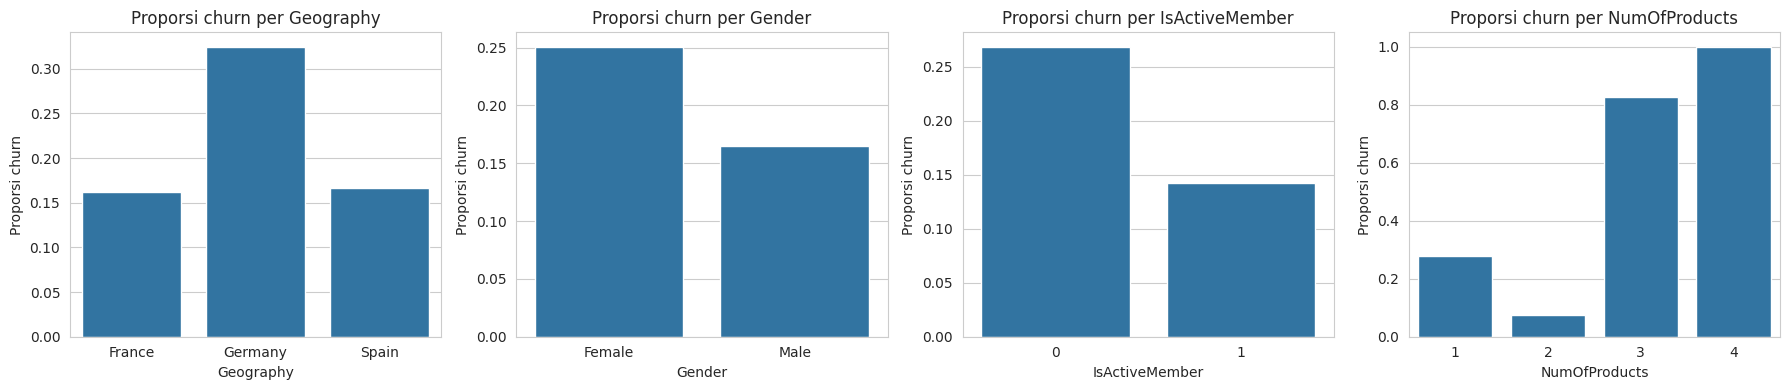

In [7]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_features = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_features):
    churn_rate = df.groupby(col)["Exited"].mean().reset_index()
    sns.barplot(data=churn_rate, x=col, y="Exited", ax=ax)
    ax.set_ylabel("Proporsi churn")
    ax.set_title(f"Proporsi churn per {col}")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

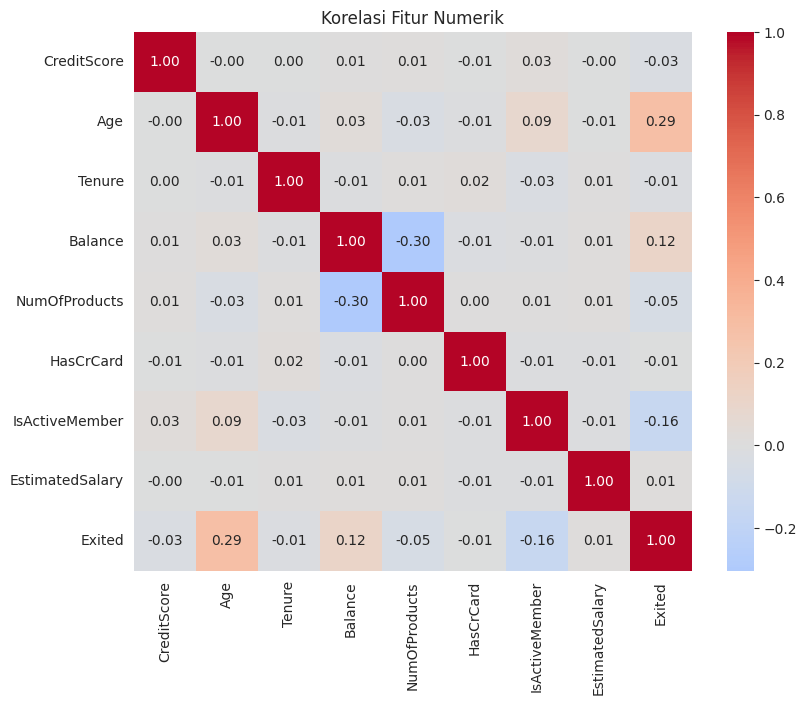

Jumlah baris duplikat: 0
Korelasi dengan Exited:
Age                0.285
IsActiveMember    -0.156
Balance            0.119
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
EstimatedSalary    0.012
HasCrCard         -0.007
Name: Exited, dtype: float64


In [8]:
# EDA tambahan: korelasi antar fitur numerik, dan pengecekan duplikat
num_df = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).select_dtypes(include="number")
plt.figure(figsize=(9, 7))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Fitur Numerik")
plt.show()

print("Jumlah baris duplikat:", df.duplicated().sum())
print("Korelasi dengan Exited:")
print(num_df.corr()["Exited"].drop("Exited").sort_values(key=abs, ascending=False).round(3))

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [9]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# Drop kolom identitas yang tidak informatif:
# - RowNumber : hanya nomor urut baris
# - CustomerId: ID unik tiap nasabah, tidak membawa pola yang bisa digeneralisasi
# - Surname   : nama belakang, kardinalitas tinggi dan tidak punya hubungan kausal dengan churn
df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).copy()

# Gender adalah kategorikal biner -> encode menjadi 0/1
df_model["Gender"] = (df_model["Gender"] == "Male").astype(int)
df_model.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0


In [10]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop(columns="Exited")
y = df_model["Exited"]

# 70% train, 15% validation, 15% test (stratified)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s}: {len(yy):5d} data | proporsi churn = {yy.mean():.3f}")

Train     :  7000 data | proporsi churn = 0.204
Validation:  1500 data | proporsi churn = 0.204
Test      :  1500 data | proporsi churn = 0.203


In [11]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography"]
# Kolom biner (Gender, HasCrCard, IsActiveMember) sudah 0/1 -> diteruskan apa adanya (passthrough)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="passthrough",
    sparse_threshold=0,
)

# fit HANYA pada train set agar tidak ada data leakage
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

input_dim = X_train_p.shape[1]
print("Bentuk fitur setelah preprocessing:", X_train_p.shape)
print("Nama fitur:", list(preprocessor.get_feature_names_out()))

Bentuk fitur setelah preprocessing: (7000, 12)
Nama fitur: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'remainder__Gender', 'remainder__HasCrCard', 'remainder__IsActiveMember']


In [12]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

def to_tensors(X_arr, y_ser):
    X_t = torch.tensor(np.asarray(X_arr, dtype=np.float32), dtype=torch.float32)
    y_t = torch.tensor(y_ser.values, dtype=torch.float32).view(-1, 1)
    return X_t, y_t

X_train_t, y_train_t = to_tensors(X_train_p, y_train)
X_val_t, y_val_t = to_tensors(X_val_p, y_val)
X_test_t, y_test_t = to_tensors(X_test_p, y_test)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
print(X_train_t.shape, y_train_t.shape)

torch.Size([7000, 12]) torch.Size([7000, 1])


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [13]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_p, y_train)

lr_pred = log_reg.predict(X_test_p)
lr_proba = log_reg.predict_proba(X_test_p)[:, 1]
print("Accuracy Logistic Regression (test):", round(accuracy_score(y_test, lr_pred), 4))

Accuracy Logistic Regression (test): 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [14]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

def count_params(model):
    return sum(p.numel() for p in model.parameters())

class SimpleANN(nn.Module):
    def __init__(self, input_dim, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),   # output berupa logit (tanpa Sigmoid)
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
simple_model = SimpleANN(input_dim)
print(simple_model)
print("Jumlah parameter:", count_params(simple_model))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [15]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def evaluate(model, X, y, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(model, criterion, optimizer, loader, epochs, verbose_every=10):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            logits = model(xb)                 # forward
            loss = criterion(logits, yb)       # hitung loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, X_train_t, y_train_t, criterion)
        va_loss, va_acc = evaluate(model, X_val_t, y_val_t, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        if (epoch + 1) % verbose_every == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
                  f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    return history

LR = 1e-3
EPOCHS = 50

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(simple_model.parameters(), lr=LR)
history_simple = train_model(simple_model, criterion, optimizer, train_loader, EPOCHS)

Epoch   1/50 | train loss 0.4911 acc 0.7963 | val loss 0.4932 acc 0.7960
Epoch  10/50 | train loss 0.3647 acc 0.8450 | val loss 0.3515 acc 0.8507
Epoch  20/50 | train loss 0.3513 acc 0.8519 | val loss 0.3361 acc 0.8533
Epoch  30/50 | train loss 0.3462 acc 0.8560 | val loss 0.3326 acc 0.8547
Epoch  40/50 | train loss 0.3431 acc 0.8556 | val loss 0.3306 acc 0.8593
Epoch  50/50 | train loss 0.3411 acc 0.8566 | val loss 0.3283 acc 0.8607


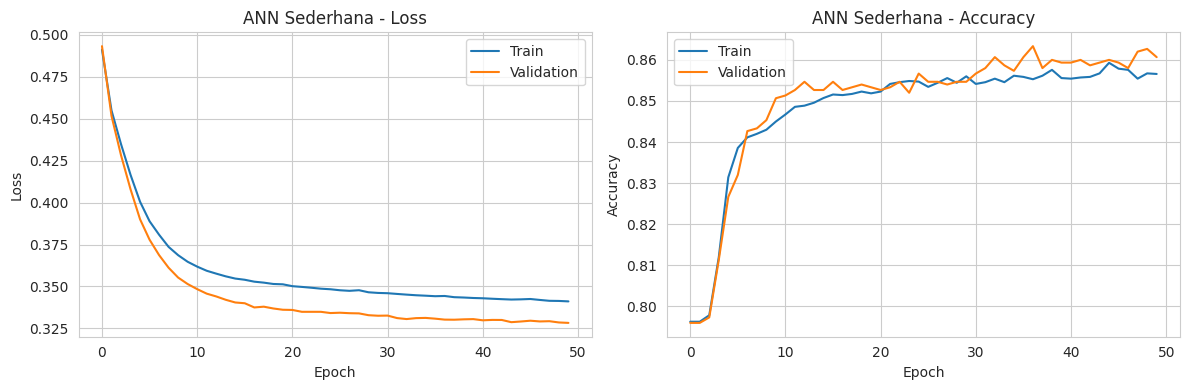

In [16]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_simple, "ANN Sederhana")

In [17]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

def predict(model, X):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        proba = torch.sigmoid(logits).view(-1).numpy()
    label = (proba >= 0.5).astype(int)
    return proba, label

simple_proba, simple_pred = predict(simple_model, X_test_t)
print("Accuracy ANN Sederhana (test):", round(accuracy_score(y_test, simple_pred), 4))

Accuracy ANN Sederhana (test): 0.8667


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [18]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
deep_model = DeepANN(input_dim)
print(deep_model)
print("Jumlah parameter:", count_params(deep_model))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1/50 | train loss 0.4569 acc 0.7963 | val loss 0.4514 acc 0.7960
Epoch  10/50 | train loss 0.3499 acc 0.8563 | val loss 0.3356 acc 0.8560
Epoch  20/50 | train loss 0.3370 acc 0.8617 | val loss 0.3332 acc 0.8620
Epoch  30/50 | train loss 0.3258 acc 0.8653 | val loss 0.3258 acc 0.8680
Epoch  40/50 | train loss 0.3200 acc 0.8670 | val loss 0.3253 acc 0.8673
Epoch  50/50 | train loss 0.3163 acc 0.8713 | val loss 0.3229 acc 0.8660


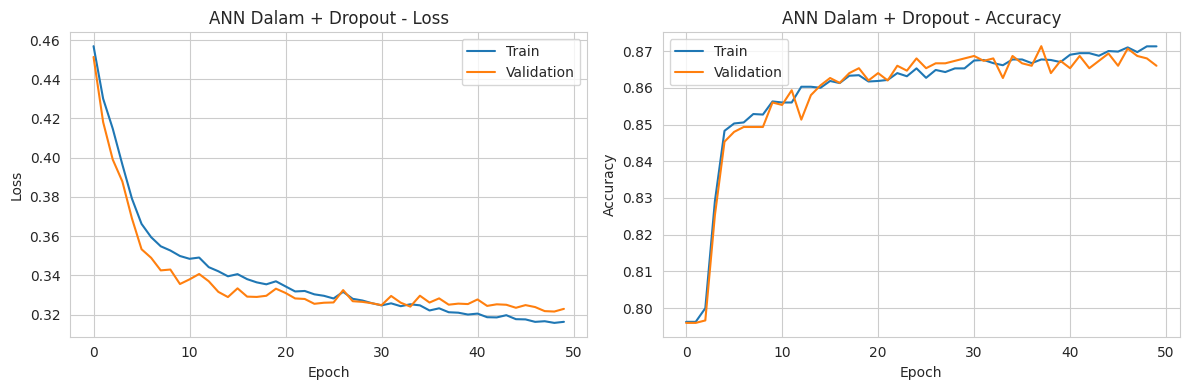

In [19]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(deep_model.parameters(), lr=LR)
history_deep = train_model(deep_model, criterion, optimizer, train_loader, EPOCHS)
plot_history(history_deep, "ANN Dalam + Dropout")
# Bandingkan selisih train vs validation dengan model 3.2 untuk menilai overfitting.

In [20]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

deep_proba, deep_pred = predict(deep_model, X_test_t)
print("Accuracy ANN Dalam + Dropout (test):", round(accuracy_score(y_test, deep_pred), 4))

Accuracy ANN Dalam + Dropout (test): 0.8673


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [21]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Pilih arsitektur terbaik berdasarkan validation loss minimum (bukan test set)
best_simple = min(history_simple["val_loss"])
best_deep = min(history_deep["val_loss"])
use_deep = best_deep < best_simple
print(f"Val loss terbaik -> ANN Sederhana: {best_simple:.4f} | ANN Dalam: {best_deep:.4f}")
print("Arsitektur yang dipakai untuk class weight:", "ANN Dalam + Dropout" if use_deep else "ANN Sederhana")

torch.manual_seed(42)   # bobot dimulai dari awal
weighted_model = DeepANN(input_dim) if use_deep else SimpleANN(input_dim)

n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
pos_weight = n_neg / n_pos
print(f"pos_weight = {n_neg} / {n_pos} = {pos_weight:.3f}")

criterion_w = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer_w = torch.optim.Adam(weighted_model.parameters(), lr=LR)
history_w = train_model(weighted_model, criterion_w, optimizer_w, train_loader, EPOCHS)

Val loss terbaik -> ANN Sederhana: 0.3283 | ANN Dalam: 0.3215
Arsitektur yang dipakai untuk class weight: ANN Dalam + Dropout
pos_weight = 5574 / 1426 = 3.909
Epoch   1/50 | train loss 0.9731 acc 0.7107 | val loss 0.9600 acc 0.7100
Epoch  10/50 | train loss 0.7408 acc 0.8037 | val loss 0.7067 acc 0.7993
Epoch  20/50 | train loss 0.7171 acc 0.7939 | val loss 0.7041 acc 0.7880
Epoch  30/50 | train loss 0.6988 acc 0.8021 | val loss 0.6957 acc 0.7967
Epoch  40/50 | train loss 0.6856 acc 0.8167 | val loss 0.6989 acc 0.8120
Epoch  50/50 | train loss 0.6719 acc 0.8129 | val loss 0.7010 acc 0.8000


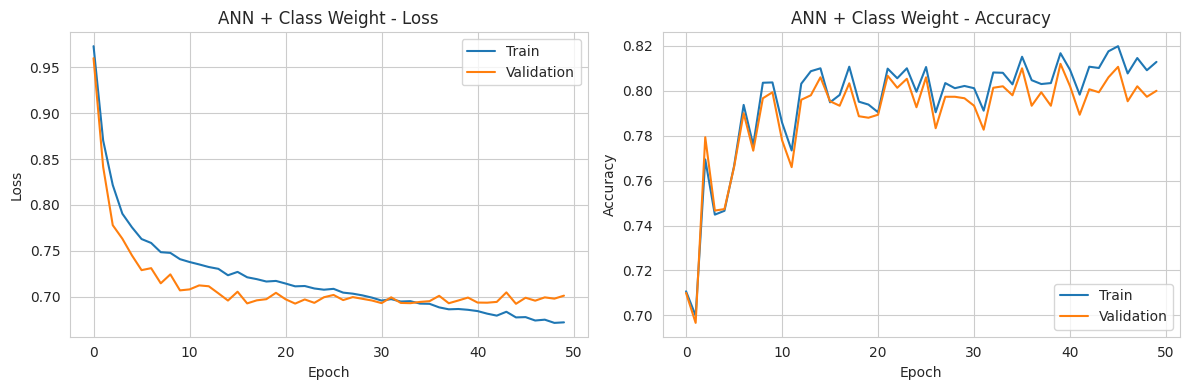

Accuracy ANN + Class Weight (test): 0.7993


In [22]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history_w, "ANN + Class Weight")

w_proba, w_pred = predict(weighted_model, X_test_t)
print("Accuracy ANN + Class Weight (test):", round(accuracy_score(y_test, w_pred), 4))

# 4. Evaluasi Model

In [23]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

results = {
    "Logistic Regression": (lr_pred, lr_proba),
    "ANN Sederhana": (simple_pred, simple_proba),
    "ANN Dalam + Dropout": (deep_pred, deep_proba),
    "ANN + Class Weight": (w_pred, w_proba),
}
y_true = y_test.values

rows = []
for name, (pred, proba) in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-Score": f1_score(y_true, pred, zero_division=0),
        "AUC": roc_auc_score(y_true, proba),
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
display(metrics_df)

,Accuracy,Precision,Recall,F1-Score,AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8667,0.7692,0.4918,0.6000,0.8679
ANN Dalam + Dropout,0.8673,0.7944,0.4689,0.5897,0.8666
ANN + Class Weight,0.7993,0.5044,0.7574,0.6055,0.8663


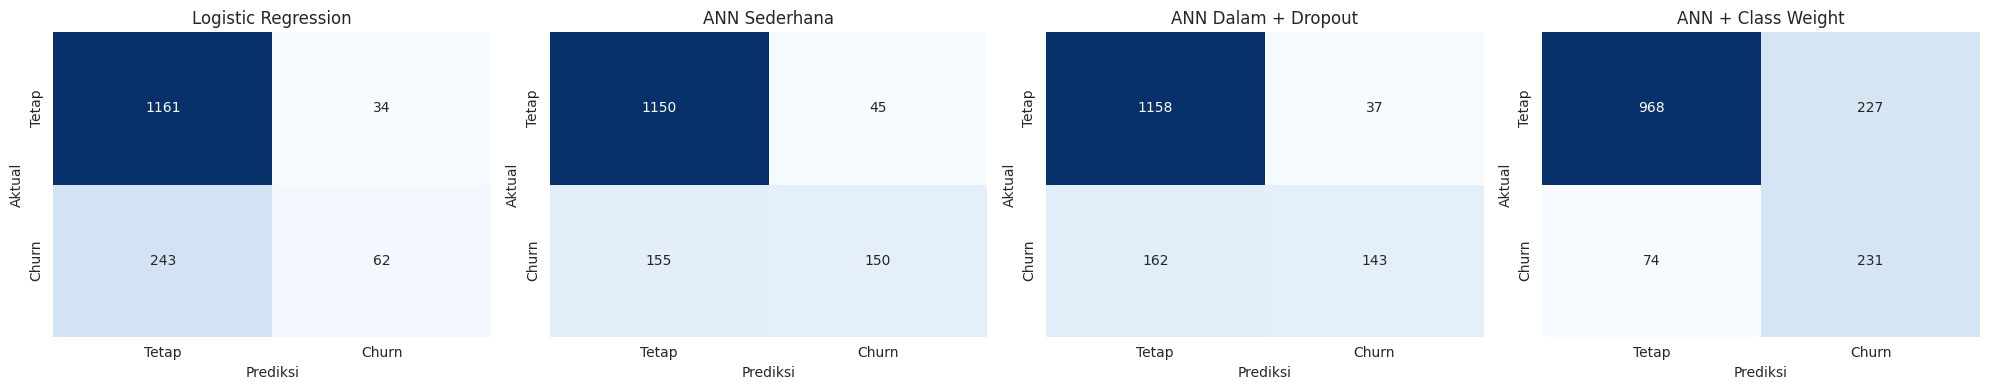

In [24]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (name, (pred, proba)) in zip(axes, results.items()):
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Tetap", "Churn"], yticklabels=["Tetap", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

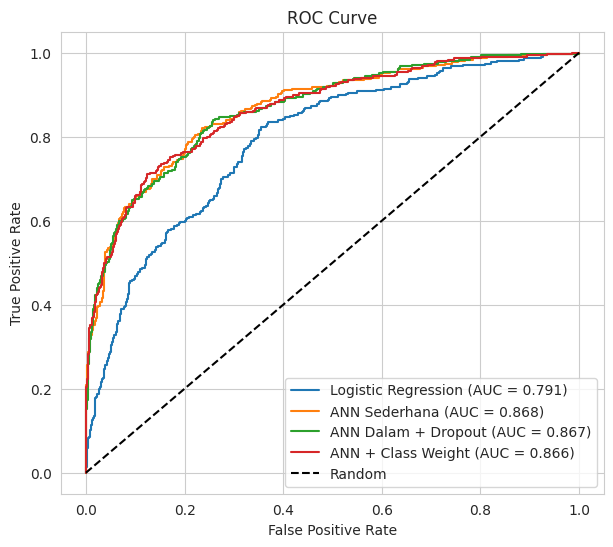

In [25]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for name, (pred, proba) in results.items():
    fpr, tpr, _ = roc_curve(y_true, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_true, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Dataset berisi 10.000 nasabah dengan 2.037 churn (20.4%). Model yang selalu menebak "tetap" sudah mencapai accuracy sekitar 79.6%, jadi angka itu menjadi patokan untuk membaca tabel evaluasi. Logistic Regression hanya sedikit di atasnya dengan accuracy 0.8153. Recall kelas churn-nya 0.2033: dari sekitar 305 nasabah churn di test set, hanya 62 yang terdeteksi dan 243 terlewat. Precision 0.6458, F1 0.3092, dan AUC 0.7913.

ANN sederhana (1 hidden layer, 16 neuron, 225 parameter) lebih baik di semua metrik: accuracy 0.8667, precision 0.7692, recall 0.4918, F1 0.6000, dan AUC 0.8679. F1 naik dari 0.31 ke 0.60 dan AUC dari 0.79 ke 0.87, selisih yang terlalu besar untuk dianggap kebetulan, sehingga ANN layak dipakai dibanding baseline. Dugaan saya, hubungan antar fitur dan churn tidak linear dan saling berinteraksi, sehingga model linear tidak bisa menangkapnya. Recall 0.49 tetap berarti 155 dari 305 nasabah churn masih terlewat.

Learning curve ANN sederhana turun bersama untuk train dan validation, lalu mendatar sekitar epoch 30. Di epoch 50 loss validation (0.3283) malah sedikit di bawah loss train (0.3411), dan accuracy validation (0.8607) sedikit di atas train (0.8566). Tidak ada tanda overfitting. Karena kedua kurva berdekatan dan model berikutnya bisa mencapai loss yang lebih rendah, ANN sederhana lebih dekat ke underfitting ringan.

ANN 3 hidden layer dengan Dropout 0.3 (3.457 parameter) memang menurunkan loss lebih jauh (validation 0.3229), tetapi metrik di test set hampir sama dengan ANN sederhana. Accuracy 0.8673 berbanding 0.8667, F1 0.5897 berbanding 0.6000, AUC 0.8666 berbanding 0.8679. Precision naik ke 0.7944 sementara recall turun ke 0.4689. Selisih accuracy hanya sekitar 1 dari 1.500 data, jadi tidak bisa disebut peningkatan. Gap train dan validation tetap kecil, artinya Dropout tidak benar-benar dibutuhkan karena model belum overfit. Kurva validation-nya lebih bergelombang (accuracy antara 0.862 dan 0.871). Dengan hanya 12 fitur, menambah layer tidak memberi informasi baru untuk dipelajari.

Class weight (pos_weight = 3.909, memakai arsitektur ANN dalam karena val loss-nya terendah) mengubah perilaku model paling besar. Recall naik dari 0.4689 ke 0.7574, jumlah nasabah churn yang terdeteksi naik dari 143 ke 231, dan False Negative turun dari 162 ke 74. Harganya precision turun dari 0.7944 ke 0.5044, False Positive naik dari 37 ke 227, dan accuracy turun dari 0.8673 ke 0.7993. F1 naik tipis dari 0.5897 ke 0.6055. AUC hampir sama (0.8663 dibanding 0.8666), jadi kemampuan model mengurutkan nasabah dari yang berisiko rendah ke tinggi tidak berubah. Class weight pada dasarnya menggeser titik keputusan sehingga model lebih mudah menyebut "churn". Kurvanya juga lebih bergelombang: accuracy validation naik turun antara 0.77 dan 0.81, dan loss validation mulai naik tipis setelah epoch 30 (0.6957 menjadi 0.7010 di epoch 50) sementara loss train terus turun (0.6988 menjadi 0.6719). Ini overfitting ringan.

Model mana yang dianggap terbaik bergantung pada tujuan. Berdasarkan AUC dan accuracy, ANN sederhana dan ANN dalam setara dan unggul. Berdasarkan recall churn, model dengan class weight jauh lebih baik. Berdasarkan F1, hanya Logistic Regression yang tertinggal jauh, sedangkan ketiga ANN berada di kisaran 0.59 sampai 0.61.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Ketiga konfigurasi ANN mengungguli Logistic Regression dengan jelas (F1 0.59 sampai 0.61 dibanding 0.31, AUC sekitar 0.87 dibanding 0.79). ANN sederhana dengan 225 parameter sudah cukup untuk data ini, karena menambah hidden layer dan Dropout hanya mengubah metrik di kisaran perbedaan acak. Class weight menaikkan recall churn dari 0.47 ke 0.76 dengan precision turun ke 0.50 dan accuracy turun ke 0.80. Model ini lebih cocok bila tujuan utamanya menjaring sebanyak mungkin nasabah yang akan pergi, dan model tanpa class weight lebih cocok bila accuracy dan precision lebih penting.

Hasil ini punya beberapa keterbatasan. Setiap model hanya dilatih sekali dengan satu seed dan satu pembagian data, sehingga selisih kecil seperti antara ANN sederhana dan ANN dalam belum bisa dipastikan. Logistic Regression juga dilatih tanpa class weight, jadi perbandingan recall-nya dengan model berbobot tidak sepenuhnya setara. Threshold klasifikasi dibiarkan 0.5 untuk semua model.

Untuk eksperimen berikutnya, saya menyarankan: melatih Logistic Regression dengan `class_weight="balanced"` sebagai pembanding yang adil, mencari threshold terbaik pada validation set lewat precision-recall curve, memakai early stopping di sekitar epoch 30 untuk model berbobot, mencoba SMOTE, dan membandingkan dengan Random Forest atau XGBoost. Mengulang eksperimen dengan beberapa seed atau cross-validation akan menunjukkan apakah perbedaan antar ANN nyata.